# Give Me Some Credit - 전처리 · 모델링 · 제출

`01.ipynb`(EDA)에서 찾은 내용을 바탕으로 전처리하고, LightGBM으로 연체 확률을 예측해 제출 파일을 만듭니다.

- **target**: `연체여부` (2년 안에 90일 이상 연체 = 1)
- **평가 지표**: AUC (연체자가 6.7%뿐인 불균형 데이터라 정확도 대신 사용)
- **제외한 feature**: `부양가족수`

| 순서 | 내용 |
|---|---|
| 1 | 데이터 불러오기 + 한글 컬럼명 + 부양가족수 제외 |
| 2 | 전처리 (training과 test에 똑같이 적용) |
| 3 | 전처리 효과 확인: 원본 vs 전처리 (교차검증 AUC) |
| 4 | HyperOpt로 하이퍼파라미터 튜닝 |
| 5 | 최종 모델 학습 · 검증 · feature 중요도 |
| 6 | cs-test 예측 → 제출 파일 저장 |

## 1. 데이터 불러오기

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)

COL_KR = {
    'SeriousDlqin2yrs': '연체여부',
    'RevolvingUtilizationOfUnsecuredLines': '신용한도사용률',
    'age': '나이',
    'NumberOfTime30-59DaysPastDueNotWorse': '연체30_59일횟수',
    'DebtRatio': '부채비율',
    'MonthlyIncome': '월소득',
    'NumberOfOpenCreditLinesAndLoans': '대출카드수',
    'NumberOfTimes90DaysLate': '연체90일이상횟수',
    'NumberRealEstateLoansOrLines': '부동산대출수',
    'NumberOfTime60-89DaysPastDueNotWorse': '연체60_89일횟수',
    'NumberOfDependents': '부양가족수',
}
TARGET = '연체여부'
DROP_COLS = ['부양가족수']

train = pd.read_csv('cs-training.csv', index_col=0).rename(columns=COL_KR).drop(columns=DROP_COLS)
test = pd.read_csv('cs-test.csv', index_col=0).rename(columns=COL_KR).drop(columns=DROP_COLS + [TARGET])   # test의 target 열은 전부 빈칸

print('train:', train.shape, ' test:', test.shape)
train.head()

train: (150000, 10)  test: (101503, 9)


,연체여부,신용한도사용률,나이,연체30_59일횟수,부채비율,월소득,대출카드수,연체90일이상횟수,부동산대출수,연체60_89일횟수
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0


## 2. 전처리

EDA에서 발견한 문제와 처리 방법입니다. 트리 기반 모델(LightGBM)은 결측치(NaN)를 스스로 처리하고 값의 크기(스케일)에 영향을 받지 않아서, 극단값을 억지로 자르기보다 **잘못된 값만 NaN으로 바꾸고 표시 열을 추가**하는 방식을 씁니다.

| 문제 | 처리 |
|---|---|
| 연체 횟수 3개 열의 96·98 (실제 횟수가 아닌 코드값, 연체율 54.6%) | `연체코드값` 표시 열 추가 + 세 열은 NaN |
| 월소득 결측 20% | `소득결측` 표시 열 추가, 값은 NaN 그대로 |
| 소득 결측자의 부채비율에는 비율이 아니라 **금액**이 들어 있음 | `부채금액` 열을 새로 만들고, 소득 결측자의 부채비율은 NaN |
| 신용한도사용률 10 초과 (최대 50,708, 비율로 볼 수 없음) | NaN (1~10 구간은 실제 위험 신호라 유지) |
| 나이 0 (1명) | NaN |
| 파생 변수 | `총연체횟수` = 연체 횟수 3개 열의 합 |

같은 함수를 training과 test에 똑같이 적용합니다.

In [2]:
LATE_COLS = ['연체30_59일횟수', '연체60_89일횟수', '연체90일이상횟수']

def preprocess(df):
    df = df.copy()

    # 1) 연체 횟수 96·98 코드값 → 표시 열 + NaN
    df['연체코드값'] = (df['연체90일이상횟수'] >= 96).astype(int)
    df.loc[df['연체코드값'] == 1, LATE_COLS] = np.nan

    # 2) 월소득 결측 표시
    income_na = df['월소득'].isna()
    df['소득결측'] = income_na.astype(int)

    # 3) 부채비율: 소득이 있으면 비율 × 소득 = 금액, 소득이 없으면 이미 금액이 들어 있음
    df['부채금액'] = np.where(income_na, df['부채비율'], df['부채비율'] * df['월소득'])
    df.loc[income_na, '부채비율'] = np.nan

    # 4) 신용한도사용률 10 초과 → NaN
    df.loc[df['신용한도사용률'] > 10, '신용한도사용률'] = np.nan

    # 5) 나이 0 → NaN
    df.loc[df['나이'] == 0, '나이'] = np.nan

    # 6) 파생 변수 (코드값 행은 NaN 유지)
    df['총연체횟수'] = df[LATE_COLS].sum(axis=1, min_count=1)

    return df

train_p = preprocess(train)
test_p = preprocess(test)

X = train_p.drop(columns=TARGET)
y = train_p[TARGET]
X_test = test_p[X.columns]          # 열 구성과 순서를 training과 똑같이

print('feature 수:', X.shape[1])
print(X.columns.tolist())

feature 수: 13
['신용한도사용률', '나이', '연체30_59일횟수', '부채비율', '월소득', '대출카드수', '연체90일이상횟수', '부동산대출수', '연체60_89일횟수', '연체코드값', '소득결측', '부채금액', '총연체횟수']


In [3]:
# 전처리 후 결측치 확인 (training / test)
pd.DataFrame({'train 결측': X.isna().sum(), 'test 결측': X_test.isna().sum()}).query('`train 결측` > 0 or `test 결측` > 0')

,train 결측,test 결측
신용한도사용률,241,153
나이,1,0
연체30_59일횟수,269,214
부채비율,29731,20103
월소득,29731,20103
연체90일이상횟수,269,214
연체60_89일횟수,269,214
총연체횟수,269,214


## 3. 전처리 효과 확인

같은 LightGBM 설정으로 **원본 데이터**(부양가족수만 제외)와 **전처리 데이터**를 5-fold 교차검증해서 AUC를 비교합니다. `stratify`처럼 연체자 비율을 fold마다 똑같이 맞추기 위해 `StratifiedKFold`를 씁니다.

In [4]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
base_params = dict(n_estimators=300, learning_rate=0.05, random_state=0, verbose=-1)

X_raw = train.drop(columns=TARGET)
auc_raw = cross_val_score(LGBMClassifier(**base_params), X_raw, y, cv=skf, scoring='roc_auc')
auc_pre = cross_val_score(LGBMClassifier(**base_params), X, y, cv=skf, scoring='roc_auc')

print(f'원본    AUC: {auc_raw.mean():.4f} (± {auc_raw.std():.4f})')
print(f'전처리  AUC: {auc_pre.mean():.4f} (± {auc_pre.std():.4f})')

원본    AUC: 0.8645 (± 0.0033)
전처리  AUC: 0.8645 (± 0.0033)


## 4. 하이퍼파라미터 튜닝 (HyperOpt)

학습 데이터를 학습용 80% / 검증용 20%로 나누고, **학습용 80% 안에서만** 3-fold 교차검증으로 좋은 설정을 찾습니다. 검증용 20%는 튜닝에 전혀 쓰지 않고 마지막 성능 확인에만 씁니다.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
print(X_train.shape, X_val.shape)
print('연체 비율  train: %.4f / val: %.4f' % (y_train.mean(), y_val.mean()))

(120000, 13) (30000, 13)
연체 비율  train: 0.0668 / val: 0.0668


In [6]:
from hyperopt import hp, fmin, tpe, Trials, STATUS_OK

lgbm_search_space = {
    'num_leaves': hp.quniform('num_leaves', 8, 64, 1),
    'min_child_samples': hp.quniform('min_child_samples', 20, 300, 10),
    'max_depth': hp.quniform('max_depth', 3, 10, 1),
    'learning_rate': hp.uniform('learning_rate', 0.01, 0.1),
    'subsample': hp.uniform('subsample', 0.6, 1.0),
    'colsample_bytree': hp.uniform('colsample_bytree', 0.5, 1.0),
    'reg_lambda': hp.uniform('reg_lambda', 0, 10),
}

def to_params(space):
    return dict(
        num_leaves=int(space['num_leaves']),
        min_child_samples=int(space['min_child_samples']),
        max_depth=int(space['max_depth']),
        learning_rate=space['learning_rate'],
        subsample=space['subsample'],
        subsample_freq=1,                      # subsample이 실제로 적용되려면 필요
        colsample_bytree=space['colsample_bytree'],
        reg_lambda=space['reg_lambda'],
    )

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)

def objective_func(space):
    model = LGBMClassifier(n_estimators=300, random_state=0, verbose=-1, **to_params(space))
    auc = cross_val_score(model, X_train, y_train, cv=cv3, scoring='roc_auc').mean()
    return {'loss': -auc, 'status': STATUS_OK}      # fmin은 최소화하므로 AUC에 - 를 붙임

trials = Trials()
best = fmin(fn=objective_func, space=lgbm_search_space, algo=tpe.suggest,
            max_evals=30, trials=trials, rstate=np.random.default_rng(0))

best_params = to_params(best)
print('최적 파라미터:', best_params)
print('튜닝 중 최고 CV AUC: %.4f' % -min(trials.losses()))

  0%|          | 0/30 [00:00<?, ?trial/s, best loss=?]

  3%|▎         | 1/30 [00:02<01:01,  2.12s/trial, best loss: -0.8638396666847843]

  7%|▋         | 2/30 [00:04<01:01,  2.21s/trial, best loss: -0.8657718426240679]

 10%|█         | 3/30 [00:06<00:59,  2.22s/trial, best loss: -0.8657879405838438]

 13%|█▎        | 4/30 [00:07<00:48,  1.87s/trial, best loss: -0.8657879405838438]

...

 93%|█████████▎| 28/30 [01:49<00:08,  4.31s/trial, best loss: -0.8663551353185878]

 97%|█████████▋| 29/30 [01:54<00:04,  4.44s/trial, best loss: -0.8663551353185878]

100%|██████████| 30/30 [01:57<00:00,  3.96s/trial, best loss: -0.8663551353185878]

100%|██████████| 30/30 [01:57<00:00,  3.91s/trial, best loss: -0.8663551353185878]


최적 파라미터: {'num_leaves': 25, 'min_child_samples': 290, 'max_depth': 4, 'learning_rate': 0.02356650290675014, 'subsample': 0.6058374306841757, 'subsample_freq': 1, 'colsample_bytree': 0.6407835110249381, 'reg_lambda': 7.699057125005118}
튜닝 중 최고 CV AUC: 0.8664


## 5. 최종 모델 학습 · 검증

튜닝한 파라미터로 학습하되, 트리 개수는 넉넉히 두고 **조기 종료(early stopping)** 로 검증 AUC가 100번 연속 좋아지지 않으면 멈춥니다.

In [7]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

final_model = LGBMClassifier(n_estimators=3000, random_state=0, verbose=-1, **best_params)
final_model.fit(X_train, y_train,
                eval_set=[(X_val, y_val)], eval_metric='auc',
                callbacks=[lgb.early_stopping(100, verbose=False)])

best_iter = final_model.best_iteration_
val_proba = final_model.predict_proba(X_val)[:, 1]
print('최적 트리 개수:', best_iter)
print('검증 AUC: %.4f' % roc_auc_score(y_val, val_proba))

최적 트리 개수: 529
검증 AUC: 0.8686


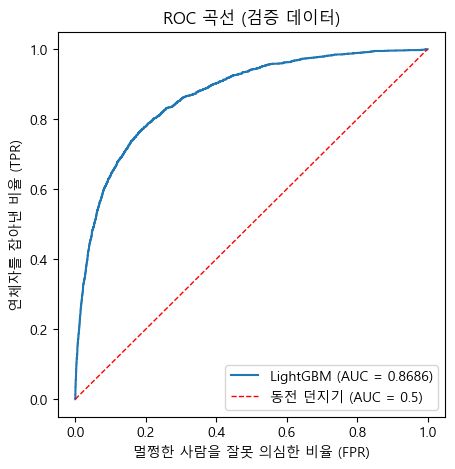

In [8]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_val, val_proba)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f'LightGBM (AUC = {roc_auc_score(y_val, val_proba):.4f})')
ax.plot([0, 1], [0, 1], 'r--', lw=1, label='동전 던지기 (AUC = 0.5)')
ax.set_xlabel('멀쩡한 사람을 잘못 의심한 비율 (FPR)')
ax.set_ylabel('연체자를 잡아낸 비율 (TPR)')
ax.set_title('ROC 곡선 (검증 데이터)')
ax.legend()
plt.show()

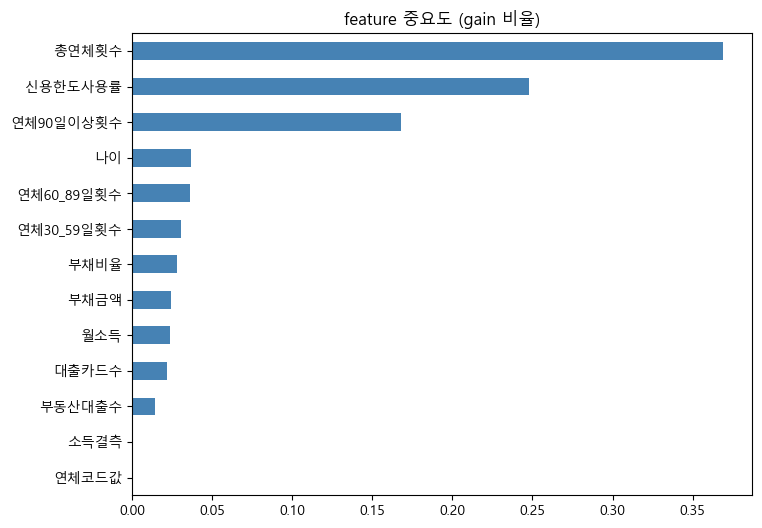

In [9]:
# feature 중요도 (트리를 나눌 때 그 feature로 얻은 이득의 합)
importance = pd.Series(final_model.booster_.feature_importance(importance_type='gain'),
                       index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
(importance / importance.sum()).plot(kind='barh', color='steelblue', ax=ax)
ax.set_title('feature 중요도 (gain 비율)')
plt.show()

## 6. cs-test 예측 → 제출 파일

검증으로 성능을 확인했으니, 마지막에는 **training 전체(100%)** 로 다시 학습합니다. 데이터가 많을수록 모델이 더 잘 배우기 때문입니다. 트리 개수는 위에서 찾은 최적 개수에 데이터가 늘어난 만큼(1 / 0.8) 조금 늘려서 씁니다.

In [10]:
n_full = int(best_iter / 0.8)
full_model = LGBMClassifier(n_estimators=n_full, random_state=0, verbose=-1, **best_params)
full_model.fit(X, y)

test_proba = full_model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({'Id': X_test.index, 'Probability': test_proba})
submission.to_csv('submission.csv', index=False)

print('트리 개수:', n_full)
print(submission.shape)
submission.head()

트리 개수: 661
(101503, 2)


,Id,Probability
0,1,0.067247
1,2,0.039704
2,3,0.016630
3,4,0.083914
4,5,0.091751


행 수 일치: True
Id 일치  : True
열 이름  : ['Id', 'Probability'] / 양식: ['Id', 'Probability']
결측 확률: 0
평균 예측 확률: 0.0670 / 학습 데이터 연체율: 0.0668


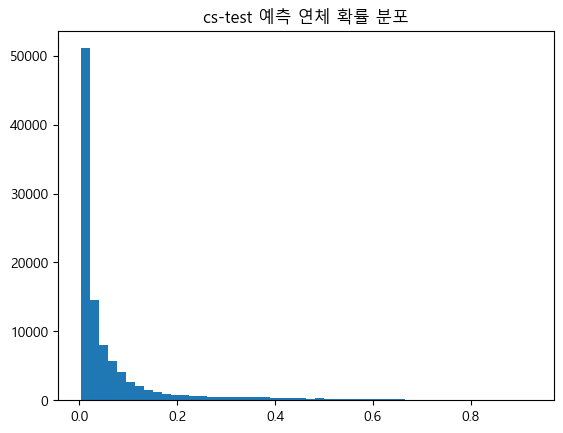

In [11]:
# 제출 양식(sampleEntry.csv)과 형식이 같은지 확인
sample = pd.read_csv('sampleEntry.csv')
print('행 수 일치:', len(sample) == len(submission))
print('Id 일치  :', (sample['Id'].values == submission['Id'].values).all())
print('열 이름  :', submission.columns.tolist(), '/ 양식:', sample.columns.tolist())
print('결측 확률:', submission['Probability'].isna().sum())

# 예측 확률 분포: 평균이 학습 데이터 연체율(약 6.7%)과 비슷하면 정상
print('평균 예측 확률: %.4f / 학습 데이터 연체율: %.4f' % (test_proba.mean(), y.mean()))
plt.hist(test_proba, bins=50)
plt.title('cs-test 예측 연체 확률 분포')
plt.show()

## 7. ch04 모델 전체 비교

ch04에서 배운 모델들을 **같은 학습용 80% (`X_train`)로 학습하고, 같은 검증용 20% (`X_val`)로 채점**해서 비교합니다. 모델 설정은 ch04 노트북에서 쓴 값을 최대한 그대로 가져왔습니다.

| 모델 | ch04 노트북 | 설정 |
|---|---|---|
| 결정트리 | 4_1 | max_depth=8, min_samples_split=16 (4_1 GridSearch 범위) |
| 로지스틱 회귀, KNN | 4_2 (보팅의 재료) | solver='liblinear' / n_neighbors=8 |
| 보팅 (LR + KNN, soft) | 4_2 | 위 두 모델의 확률 평균 |
| 랜덤포레스트 | 4_2 | n_estimators=300, max_depth=10, min_samples_leaf=8, min_samples_split=8 |
| GBM | 4_2 | 기본값 (트리 100개) |
| AdaBoost | 4_7 (스태킹의 재료) | n_estimators=100 |
| XGBoost | 4_3 | n_estimators=400, learning_rate=0.1, max_depth=3 |
| LightGBM 기본 | 4_4 | n_estimators=400 |
| LightGBM 튜닝 | 4_5 · 4_6 (HyperOpt) | 위 4~5장에서 만든 최종 모델 |
| 스태킹 | 4_7 | 기반 모델 KNN · 랜덤포레스트 · 결정트리 · AdaBoost → 최종 모델 로지스틱 회귀 (C=10) |

**모델별로 데이터를 맞춰 주는 처리**

- XGBoost와 LightGBM은 결측치(NaN)를 스스로 처리하지만, scikit-learn 모델(결정트리, 랜덤포레스트, GBM, AdaBoost, 로지스틱 회귀, KNN)은 NaN이 있으면 에러가 납니다. 그래서 `SimpleImputer`로 **결측치를 학습 데이터의 중앙값으로 채웁니다.**
- 로지스틱 회귀와 KNN은 값의 크기(스케일)와 극단값에 크게 휘둘리는 모델이라, **log 변환 → 표준화(`StandardScaler`)** 를 추가합니다. 전처리 후 모든 feature가 0 이상이라 `log1p`를 쓸 수 있습니다.
- `make_pipeline`으로 묶으면 이 처리가 학습 데이터 기준으로만 계산되고, 검증 데이터에는 같은 기준이 그대로 적용됩니다.

비교 기준으로 **"전부 0(정상)으로 찍기"** 도 함께 넣었습니다. 정확도와 AUC의 차이를 보기 위해서입니다.

In [12]:
import time
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

def imputed(model):
    # 결측치를 중앙값으로 채운 뒤 모델에 넣기 (트리 계열 scikit-learn 모델용)
    return make_pipeline(SimpleImputer(strategy='median'), model)

def scaled(model):
    # 결측치 채우기 → log 변환 → 표준화 → 모델 (로지스틱 회귀, KNN용)
    return make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p),
                         StandardScaler(), model)

models = {
    '전부 0으로 찍기 (기준)': DummyClassifier(strategy='most_frequent'),
    '결정트리 (4_1)': imputed(DecisionTreeClassifier(max_depth=8, min_samples_split=16, random_state=0)),
    '로지스틱 회귀': scaled(LogisticRegression(solver='liblinear')),
    'KNN': scaled(KNeighborsClassifier(n_neighbors=8)),
    '보팅 LR+KNN (4_2)': VotingClassifier(
        estimators=[('LR', scaled(LogisticRegression(solver='liblinear'))),
                    ('KNN', scaled(KNeighborsClassifier(n_neighbors=8)))],
        voting='soft'),
    '랜덤포레스트 (4_2)': imputed(RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=8,
                                                     min_samples_split=8, random_state=0, n_jobs=-1)),
    'GBM (4_2)': imputed(GradientBoostingClassifier(random_state=0)),
    'AdaBoost': imputed(AdaBoostClassifier(n_estimators=100, random_state=0)),
    'XGBoost (4_3)': XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=3, random_state=0, n_jobs=-1),
    'LightGBM 기본 (4_4)': LGBMClassifier(n_estimators=400, random_state=0, verbose=-1),
    '스태킹 (4_7)': StackingClassifier(
        estimators=[('KNN', scaled(KNeighborsClassifier(n_neighbors=4))),
                    ('RF', imputed(RandomForestClassifier(n_estimators=100, random_state=0))),
                    ('DT', imputed(DecisionTreeClassifier(max_depth=8, random_state=0))),
                    ('ADA', imputed(AdaBoostClassifier(n_estimators=100, random_state=0)))],
        final_estimator=LogisticRegression(C=10, max_iter=1000),
        stack_method='predict_proba', cv=5, n_jobs=-1),
}

학습 데이터가 12만 행이라 GBM과 스태킹은 몇 분 걸립니다. 스태킹은 4_7의 `get_stacking_base_datasets`처럼 학습 데이터를 5개 fold로 나눠 기반 모델의 예측값을 만들고, 그 예측값으로 최종 모델을 학습합니다. scikit-learn의 `StackingClassifier`가 이 과정을 자동으로 해 줍니다.

In [13]:
results = []
probas = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_val)[:, 1]
    elapsed = time.time() - start

    probas[name] = proba
    results.append({'모델': name,
                    '검증 AUC': roc_auc_score(y_val, proba),
                    '정확도': accuracy_score(y_val, (proba >= 0.5).astype(int)),
                    '시간(초)': elapsed})
    print(f'{name:22s} AUC = {results[-1]["검증 AUC"]:.4f}   ({elapsed:.1f}초)')

# 5장에서 만든 튜닝된 LightGBM도 같은 검증 데이터 결과로 추가
name = 'LightGBM 튜닝 (4_5·4_6)'
probas[name] = val_proba
results.append({'모델': name,
                '검증 AUC': roc_auc_score(y_val, val_proba),
                '정확도': accuracy_score(y_val, (val_proba >= 0.5).astype(int)),
                '시간(초)': np.nan})

result_df = pd.DataFrame(results).set_index('모델').sort_values('검증 AUC', ascending=False)
result_df.round(4)

전부 0으로 찍기 (기준)         AUC = 0.5000   (0.0초)


결정트리 (4_1)             AUC = 0.8485   (0.5초)


로지스틱 회귀                AUC = 0.8588   (0.4초)


KNN                    AUC = 0.7783   (14.4초)


보팅 LR+KNN (4_2)        AUC = 0.8494   (12.3초)


...

AdaBoost               AUC = 0.8647   (7.7초)


XGBoost (4_3)          AUC = 0.8678   (10.4초)


LightGBM 기본 (4_4)      AUC = 0.8615   (1.0초)


스태킹 (4_7)              AUC = 0.8641   (52.9초)


,검증 AUC,정확도,시간(초)
모델,,,
LightGBM 튜닝 (4_5·4_6),0.8686,0.9366,NaN
XGBoost (4_3),0.8678,0.9373,10.3837
GBM (4_2),0.8667,0.9363,14.3679
랜덤포레스트 (4_2),0.8664,0.9375,3.0858
AdaBoost,0.8647,0.9349,7.6567
스태킹 (4_7),0.8641,0.9361,52.8634
LightGBM 기본 (4_4),0.8615,0.9351,1.0288
로지스틱 회귀,0.8588,0.9366,0.3819
보팅 LR+KNN (4_2),0.8494,0.9369,12.3445


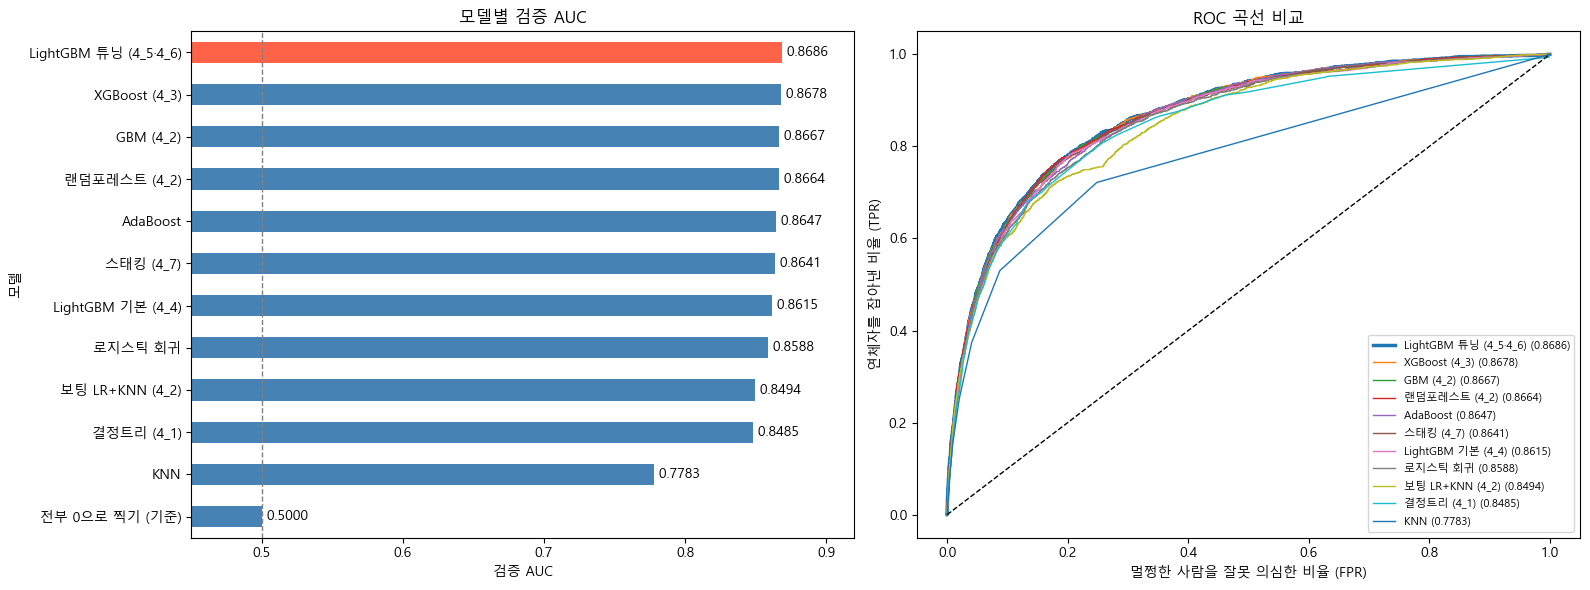

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 왼쪽: AUC 비교
auc_sorted = result_df['검증 AUC'].sort_values()
colors = ['tomato' if '튜닝' in n else 'steelblue' for n in auc_sorted.index]
auc_sorted.plot(kind='barh', color=colors, ax=axes[0])
for i, v in enumerate(auc_sorted):
    axes[0].text(v, i, f' {v:.4f}', va='center')
axes[0].axvline(0.5, color='gray', ls='--', lw=1)
axes[0].set_xlim(0.45, 0.92)
axes[0].set_xlabel('검증 AUC')
axes[0].set_title('모델별 검증 AUC')

# 오른쪽: ROC 곡선 (기준 모델 제외)
for name in result_df.index:
    if name.startswith('전부 0'):
        continue
    fpr, tpr, _ = roc_curve(y_val, probas[name])
    axes[1].plot(fpr, tpr, lw=2.5 if '튜닝' in name else 1,
                 label=f'{name} ({result_df.loc[name, "검증 AUC"]:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('멀쩡한 사람을 잘못 의심한 비율 (FPR)')
axes[1].set_ylabel('연체자를 잡아낸 비율 (TPR)')
axes[1].set_title('ROC 곡선 비교')
axes[1].legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.show()

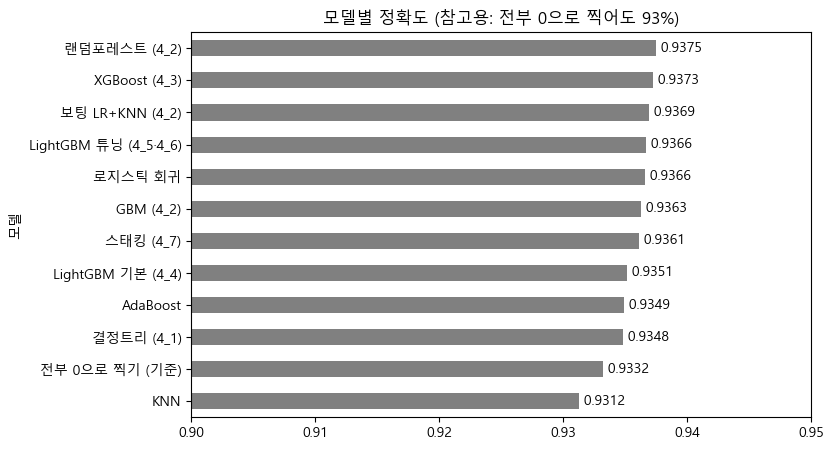

In [15]:
# 정확도는 모든 모델이 비슷하게 높아서 모델 간 차이를 보여주지 못함
fig, ax = plt.subplots(figsize=(8, 5))
acc_sorted = result_df['정확도'].sort_values()
acc_sorted.plot(kind='barh', color='gray', ax=ax)
for i, v in enumerate(acc_sorted):
    ax.text(v, i, f' {v:.4f}', va='center')
ax.set_xlim(0.9, 0.95)
ax.set_title('모델별 정확도 (참고용: 전부 0으로 찍어도 93%)')
plt.show()

### 7-1. 모델 비교표

ch04의 `get_clf_eval` 함수에서 쓴 평가 지표를 모델마다 한 표로 모았습니다. 노란색은 각 열에서 가장 좋은 값입니다.

| 지표 | 뜻 |
|---|---|
| AUC | 연체자를 정상인보다 위험하다고 순서를 맞게 매기는 확률 (**이 프로젝트의 기준 지표**) |
| 정확도 | 전체 중 맞힌 비율 |
| 정밀도 | 연체라고 예측한 사람 중 실제 연체자 비율 ("의심한 사람이 진짜였나?") |
| 재현율 | 실제 연체자 중 잡아낸 비율 ("연체자를 얼마나 놓치지 않았나?") |
| F1 | 정밀도와 재현율의 조화 평균 |

정확도 · 정밀도 · 재현율 · F1은 **확률 0.5 이상이면 연체**로 판정한 결과입니다. 표는 보고서에 쓸 수 있게 `model_comparison.csv`로도 저장합니다.

In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

rows = []
for name in result_df.index:
    proba = probas[name]
    pred = (proba >= 0.5).astype(int)
    rows.append({'모델': name,
                 'AUC': roc_auc_score(y_val, proba),
                 '정확도': accuracy_score(y_val, pred),
                 '정밀도': precision_score(y_val, pred, zero_division=0),
                 '재현율': recall_score(y_val, pred),
                 'F1': f1_score(y_val, pred),
                 '시간(초)': result_df.loc[name, '시간(초)']})

compare_df = pd.DataFrame(rows).set_index('모델')
compare_df.insert(0, '순위', compare_df['AUC'].rank(ascending=False, method='min').astype(int))
compare_df.insert(2, '1위와 AUC 차이', compare_df['AUC'] - compare_df['AUC'].max())
compare_df.to_csv('model_comparison.csv', encoding='utf-8-sig')    # 엑셀에서 한글이 안 깨지게 utf-8-sig

metric_cols = ['AUC', '정확도', '정밀도', '재현율', 'F1']
fmt = {**{c: '{:.4f}' for c in metric_cols}, '1위와 AUC 차이': '{:+.4f}', '시간(초)': '{:.1f}'}

(compare_df.style
    .format(fmt, na_rep='-')
    .background_gradient(subset=['AUC'], cmap='Blues', vmin=0.75)
    .highlight_max(subset=metric_cols, color='#ffd54f')
    .bar(subset=['시간(초)'], color='#f4a6a6')
    .set_caption('ch04 모델 비교 (검증 데이터 30,000명, 임계값 0.5)'))

,순위,AUC,1위와 AUC 차이,정확도,정밀도,재현율,F1,시간(초)
모델,,,,,,,,
LightGBM 튜닝 (4_5·4_6),1,0.8686,+0.0000,0.9366,0.5800,0.1880,0.2840,-
XGBoost (4_3),2,0.8678,-0.0009,0.9373,0.5945,0.1930,0.2914,10.4
GBM (4_2),3,0.8667,-0.0020,0.9363,0.5708,0.1890,0.2840,14.4
랜덤포레스트 (4_2),4,0.8664,-0.0022,0.9375,0.6150,0.1721,0.2689,3.1
AdaBoost,5,0.8647,-0.0039,0.9349,0.5324,0.2090,0.3001,7.7
스태킹 (4_7),6,0.8641,-0.0046,0.9361,0.5615,0.2005,0.2955,52.9
LightGBM 기본 (4_4),7,0.8615,-0.0072,0.9351,0.5416,0.1915,0.2830,1.0
로지스틱 회귀,8,0.8588,-0.0099,0.9366,0.5774,0.1915,0.2876,0.4
보팅 LR+KNN (4_2),9,0.8494,-0.0192,0.9369,0.5832,0.1975,0.2951,12.3


### 7-2. 비교 결과 해석

| 순위 | 모델 | 검증 AUC |
|---|---|---|
| 1 | LightGBM 튜닝 | 0.8686 |
| 2 | XGBoost | 0.8678 |
| 3 | GBM | 0.8667 |
| 4 | 랜덤포레스트 | 0.8664 |
| 5 | AdaBoost | 0.8647 |
| 6 | 스태킹 | 0.8641 |
| 7 | LightGBM 기본 | 0.8615 |
| 8 | 로지스틱 회귀 | 0.8588 |
| 9 | 보팅 (LR + KNN) | 0.8494 |
| 10 | 결정트리 | 0.8485 |
| 11 | KNN | 0.7783 |
| - | 전부 0으로 찍기 | 0.5000 |

**1. 앙상블 트리 모델이 상위권을 차지했고, 그 안에서는 차이가 아주 작습니다.**
1~6위가 0.864~0.869 사이에 모여 있습니다. 3장의 교차검증에서 fold마다 AUC가 ±0.003 정도 흔들렸으니, 0.001~0.002 차이는 검증 데이터를 어떻게 나눴느냐에 따라 순위가 바뀔 수 있는 수준입니다. "튜닝한 LightGBM이 압도적으로 좋다"기보다는 **"부스팅 · 랜덤포레스트 계열이 이 데이터에 잘 맞는다"** 가 정확한 결론입니다.

**2. 같은 LightGBM도 튜닝 여부에 따라 0.007 차이가 납니다.**
기본 설정(0.8615)은 트리 400개를 학습률 0.1로 깊게 쌓아서 학습 데이터에 과적합됐습니다. 튜닝 모델은 얕은 트리(max_depth=4), 큰 리프 최소 샘플 수(290), 낮은 학습률로 과적합을 막았습니다. **LightGBM은 기본값보다 튜닝이 중요한 모델**이라는 걸 보여 줍니다.

**3. 트리 1개(결정트리 0.8485) → 트리 여러 개(랜덤포레스트 0.8664)로 크게 좋아졌습니다.**
4_2에서 배운 앙상블 효과입니다. 트리 하나는 데이터에 따라 결과가 크게 흔들리지만, 여러 트리의 예측을 평균하면 안정됩니다.

**4. KNN이 가장 낮고, 보팅에 섞으니 로지스틱 회귀까지 끌어내렸습니다.**
- KNN(n_neighbors=8)은 주변 8명 중 연체자 비율로 확률을 내기 때문에, 확률이 0, 1/8, 2/8, … 처럼 **9가지 값밖에 없습니다.** 순서를 세밀하게 매기지 못해서 AUC가 낮고, ROC 곡선도 각진 모양입니다.
- 보팅(0.8494)은 로지스틱 회귀 단독(0.8588)보다 낮습니다. **약한 모델을 섞으면 평균이 오히려 나빠질 수 있습니다.**

**5. 스태킹은 시간 대비 효과가 없었습니다.**
가장 오래 걸렸지만(약 50초) 기반 모델 중 가장 좋은 랜덤포레스트(0.8664)보다 낮습니다. 기반 모델에 KNN과 결정트리처럼 약한 모델이 섞여 있기 때문입니다. 스태킹은 **서로 다르면서 각자 성능도 좋은 모델**을 모았을 때 효과가 있습니다.

**6. 정확도로는 모델을 구분할 수 없습니다.**
모든 모델의 정확도가 0.931~0.938 사이이고, "전부 0으로 찍기"도 0.933입니다. KNN은 오히려 찍기보다 정확도가 낮습니다. 불균형 데이터에서 **정확도 대신 AUC를 쓰는 이유**가 그대로 드러납니다.

**7. 임계값 0.5에서는 모든 모델이 연체자의 약 20%만 잡아냅니다.**
재현율이 0.17~0.25 수준입니다. 연체자가 6.7%뿐이라 모델이 확률을 0.5 이상으로 주는 경우가 드물기 때문입니다. 특히 KNN은 AUC가 가장 낮은데 재현율과 F1은 가장 높습니다. 정밀도 · 재현율 · F1은 **어떤 임계값을 쓰느냐에 따라 순위가 바뀌는 지표**이고, AUC는 임계값과 상관없이 순서를 매기는 능력만 보기 때문에 모델 비교 기준으로 AUC를 씁니다. 실제로 연체자를 더 많이 잡고 싶다면 임계값을 0.5보다 낮춰서(예: 0.2) 재현율을 높이는 방식으로 조정합니다.

**최종 선택:** AUC가 가장 높고 학습도 빠른 **튜닝된 LightGBM**을 제출 모델로 유지합니다 (6장의 `submission.csv`).


## 정리

- 부양가족수를 제외하고, EDA에서 찾은 문제를 표시 열 + NaN 방식으로 처리했습니다.
- 전처리 전후 AUC 비교, HyperOpt 튜닝, 조기 종료를 거쳐 최종 모델을 만들었습니다.
- 결과 파일: `submission.csv` (`Id`, `Probability`) → Kaggle "Give Me Some Credit" 대회 페이지의 Late Submission으로 제출하면 test 점수를 확인할 수 있습니다.
- ch04의 모델 11개를 같은 데이터로 비교한 결과, 부스팅 · 랜덤포레스트 계열이 상위권이었고 튜닝된 LightGBM이 검증 AUC 0.8686으로 가장 높았습니다.